# Modelos de pronóstico de series de tiempo: familia LTSF-Linear

Los siete clasificadores anteriores reciben un conjunto de predictores construido a partir del
conocimiento hidrológico del río: rezagos del caudal de Calamar, el caudal de Puerto Salgar
desfasado por su tiempo de tránsito, armónicos estacionales y la distancia del caudal actual a la
descarga efectiva. Una alternativa es tratar el problema como pronóstico de una serie de tiempo y
dejar que el modelo aprenda directamente de la historia del caudal. La referencia actual para esa
alternativa es la familia LTSF-Linear de pronóstico de largo plazo {cite}`zeng2023`, que mostró
que modelos lineales simples superan a las arquitecturas basadas en transformers en los conjuntos
de referencia del área.

La familia tiene tres miembros. Linear es una capa lineal sobre la ventana de historia del
logaritmo del caudal; NLinear resta antes a la ventana su último valor, lo que protege al modelo
de los cambios de nivel entre periodos; y DLinear descompone la ventana con una media móvil en
tendencia y estacionalidad y proyecta cada componente con su propia capa lineal. Los tres
pronostican el cambio logarítmico del caudal a quince días, $z = \log(Q_{t+15}/Q_t)$, con hasta 365
días de historia de Calamar y, si la optimización lo elige, de Puerto Salgar. Como son
pronosticadores puntuales, la probabilidad de banda se obtiene suponiendo un residuo gaussiano,
cuya dispersión se estima fuera de muestra en el último 15 % cronológico del entrenamiento, e
integrando esa distribución entre los límites de la banda.

Los tres modelos se evaluaron con el mismo protocolo que los demás: las mismas doce particiones
externas, la misma validación interna, la misma semilla y el mismo presupuesto de 16 evaluaciones,
con TPE como optimizador. Sus hiperparámetros son la longitud de la ventana, la penalización L2,
los canales de entrada y, en DLinear, el tamaño de la media móvil.

In [1]:
# Resultados por bloque de los modelos LTSF-Linear y de la mejor combinación de cada clasificador
import sys, pickle, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scipy.stats as st
from myst_nb import glue
from sklearn.metrics import average_precision_score
from src import estilo
from src.estilo import RIO, SED, CAU, ALE, NEU
from src.config import RESULTADOS
from src.analysis import tabla_pliegues
from src.models import NOMBRES_MODELO
from src.stats_tests import holm, bootstrap_bloques, longitud_bloque
from src.experiment import cargar_datos
D = cargar_datos(); E = RESULTADOS / "estadistica"
LTSF = {"linear": "Linear", "nlinear": "NLinear", "dlinear": "DLinear"}
NM = {**NOMBRES_MODELO, **LTSF}
universo = pd.read_csv(E / "universo_pliegues.csv", index_col=0)
ltsf = tabla_pliegues("ltsf_calamar").pivot_table(index="pliegue", columns="modelo", values="pr_auc")[list(LTSF)]
tabla = universo.join(ltsf)
bloques = tabla_pliegues("ltsf_calamar").drop_duplicates("pliegue").set_index("pliegue").bloque
ref = universo.mean().idxmax()

In [2]:
# Código fuente de los tres modelos (src/dlinear.py)
import inspect
from IPython.display import Code
from src import dlinear
Code("\n\n".join(inspect.getsource(o) for o in (dlinear.media_movil, dlinear.DLinear, dlinear.Linear, dlinear.NLinear)),
     language="python")

def media_movil(x: np.ndarray, kernel: int) -> np.ndarray:
    """Media móvil centrada con relleno replicado en los extremos, como en DLinear.

    Parameters
    ----------
    x : array (n, L)
        Ventanas ordenadas de la más antigua a la más reciente.
    kernel : int
        Tamaño impar de la ventana de la media móvil.
    """
    m = (kernel - 1) // 2
    relleno = np.concatenate([np.repeat(x[:, :1], m, axis=1), x, np.repeat(x[:, -1:], m, axis=1)], axis=1)
    acumulada = np.cumsum(np.pad(relleno, ((0, 0), (1, 0))), axis=1)
    return (acumulada[:, kernel:] - acumulada[:, :-kernel]) / kernel


class DLinear(RegressorMixin, BaseEstimator):
    """DLinear de un paso: tendencia y estacionalidad proyectadas por dos capas lineales.

    Parameters
    ----------
    longitud : int
        Días de historia de la ventana (≤ 365).
    kernel : int
        Tamaño de la media móvil de la descomposición; se fuerza a impar.
    alpha : float
        Penalización L2 de las capas lineales.
    canales : str
        ``"calamar"`` (univariado, como el DLinear original) o ``"ambos"`` (añade Puerto Salgar
        como covariable).
    """

    def __init__(self, longitud: int = 90, kernel: int = 25, alpha: float = 1e-3, canales: str = "calamar"):
        self.longitud = longitud
        self.kernel = kernel
        self.alpha = alpha
        self.canales = canales

    def _entrada(self, W: pd.DataFrame) -> np.ndarray:
        nombres = ["calamar"] if self.canales == "calamar" else ["calamar", "pto_salgar"]
        L = int(self.longitud)
        k = min(int(self.kernel) | 1, L if L % 2 else L - 1)   # impar y no mayor que la ventana
        partes = []
        for c in nombres:
            pre = CANALES[c]
            cols = [f"{pre}_{i}" for i in range(L - 1, -1, -1)]  # de la más antigua a la más reciente
            x = np.log(W[cols].to_numpy(dtype=np.float64))
            tendencia, estacional = descomponer(x, k)
            partes += [tendencia, estacional]
        return np.hstack(partes)

    def fit(self, W: pd.DataFrame, z: np.ndarray):
        self.lineal_ = Ridge(alpha=self.alpha).fit(self._entrada(W), np.asarray(z, dtype=np.float64))
        return self

    def predict(self, W: pd.DataFrame) -> np.ndarray:
        return self.lineal_.predict(self._entrada(W))


class Linear(DLinear):
    """Linear de LTSF-Linear: una sola capa lineal sobre la ventana sin transformar.

    La capa predice el nivel futuro, ``log Q(t+15)``, a partir de los logaritmos de la ventana;
    el cambio logarítmico se recupera restando ``log Q(t)``. ``kernel`` no interviene.
    """

    def _ventanas(self, W: pd.DataFrame) -> list[np.ndarray]:
        nombres = ["calamar"] if self.canales == "calamar" else ["calamar", "pto_salgar"]
        L = int(self.longitud)
        return [np.log(W[[f"{CANALES[c]}_{i}" for i in range(L - 1, -1, -1)]].to_numpy(dtype=np.float64))
                for c in nombres]

    def _entrada(self, W: pd.DataFrame) -> np.ndarray:
        return np.hstack(self._ventanas(W))

    @staticmethod
    def _nivel_actual(W: pd.DataFrame) -> np.ndarray:
        return np.log(W["cal_0"].to_numpy(dtype=np.float64))

    def fit(self, W: pd.DataFrame, z: np.ndarray):
        nivel = np.asarray(z, dtype=np.float64) + self._nivel_actual(W)
        self.lineal_ = Ridge(alpha=self.alpha).fit(self._entrada(W), nivel)
        return self

    def predict(self, W: pd.DataFrame) -> np.ndarray:
        return self.lineal_.predict(self._entrada(W)) - self._nivel_actual(W)


class NLinear(Linear):
    """NLinear de LTSF-Linear: la capa lineal actúa sobre la ventana menos su último valor.

    La normalización resta a cada canal su valor más reciente y lo suma de nuevo a la salida,
    lo que protege al modelo de los cambios de nivel entre el entrenamiento y la prueba. Como
    el último valor de Calamar es ``log Q(t)``, la salida normalizada es directamente el cambio
    logarítmico ``z``.
    """

    def _entrada(self, W: pd.DataFrame) -> np.n

## Desempeño en la validación anidada

La tabla compara la PR-AUC externa de los tres modelos con la de la mejor combinación de cada
clasificador, y contrasta cada modelo LTSF-Linear con {glue:text}`ref_nombre`, el mejor
clasificador, con la prueba de Wilcoxon unilateral sobre los doce bloques pareados y la
corrección de Holm.

In [3]:
# PR-AUC externa de los diez modelos; Wilcoxon-Holm de cada LTSF-Linear frente al mejor clasificador
filas = []
for m in tabla.mean().sort_values(ascending=False).index:
    fila = {"Modelo": NM[m], "Familia": "LTSF-Linear" if m in LTSF else "Clasificador",
            "PR-AUC externa": f"{tabla[m].mean():.3f} ± {tabla[m].std():.3f}",
            "Rango medio": tabla.rank(axis=1, ascending=False)[m].mean()}
    if m in LTSF:
        fila.update({"Bloques en que gana " + NM[ref]: int((tabla[ref] > tabla[m]).sum()),
                     "p Wilcoxon": st.wilcoxon(tabla[ref], tabla[m], alternative="greater", zero_method="zsplit").pvalue})
    filas.append(fila)
comp = pd.DataFrame(filas)
mask = comp["p Wilcoxon"].notna()
comp.loc[mask, "p Wilcoxon (Holm)"] = holm(comp.loc[mask, "p Wilcoxon"].values)
fr_ltsf = st.friedmanchisquare(*[tabla[m] for m in LTSF])
p_log = holm(np.array([st.wilcoxon(tabla[m], tabla["logistica"], zero_method="zsplit").pvalue for m in LTSF]))
p_nb = holm(np.array([st.wilcoxon(tabla[m], tabla["naive_bayes"], alternative="greater", zero_method="zsplit").pvalue for m in LTSF]))
ext = tabla[list(LTSF)].mean()
glue("ref_nombre", NM[ref], display=False)
glue("ltsf_ext_min", float(ext.min()), display=False); glue("ltsf_ext_max", float(ext.max()), display=False)
glue("ltsf_mejor", NM[ext.idxmax()], display=False)
glue("ltsf_fr_p", float(fr_ltsf.pvalue), display=False)
glue("ltsf_p_log_min", float(p_log.min()), display=False); glue("ltsf_p_nb_max", float(p_nb.max()), display=False)
glue("log_ext", float(tabla["logistica"].mean()), display=False); glue("arbol_ext", float(tabla["arbol"].mean()), display=False)
glue("ref_ext", float(tabla[ref].mean()), display=False)
for m in LTSF:
    r = comp[comp.Modelo == NM[m]].iloc[0]
    glue(f"{m}_p_holm", float(r["p Wilcoxon (Holm)"]), display=False)
    glue(f"{m}_vict", int(r["Bloques en que gana " + NM[ref]]), display=False)
comp.round(4)

,Modelo,Familia,PR-AUC externa,Rango medio,Bloques en que gana Random Forest,p Wilcoxon,p Wilcoxon (Holm)
0,Random Forest,Clasificador,0.910 ± 0.075,2.7500,NaN,NaN,NaN
1,XGBoost,Clasificador,0.905 ± 0.060,3.7500,NaN,NaN,NaN
2,KNN,Clasificador,0.888 ± 0.113,4.5833,NaN,NaN,NaN
3,SVM,Clasificador,0.886 ± 0.139,4.2500,NaN,NaN,NaN
4,Linear,LTSF-Linear,0.871 ± 0.087,5.5000,9.0,0.0549,0.0549
5,Árbol de decisión,Clasificador,0.866 ± 0.091,6.3333,NaN,NaN,NaN
6,DLinear,LTSF-Linear,0.855 ± 0.092,6.2500,10.0,0.0081,0.0161
7,Regresión logística,Clasificador,0.850 ± 0.136,5.5833,NaN,NaN,NaN
8,NLinear,LTSF-Linear,0.847 ± 0.102,6.3333,11.0,0.0034,0.0103
9,Naive Bayes,Clasificador,0.705 ± 0.187,9.6667,NaN,NaN,NaN


Los tres modelos LTSF-Linear alcanzan PR-AUC externas medias entre {glue:text}`ltsf_ext_min:.3f` y
{glue:text}`ltsf_ext_max:.3f`, y se ubican en el grupo intermedio de la tabla, junto a la
regresión logística ({glue:text}`log_ext:.3f`) y el árbol de decisión ({glue:text}`arbol_ext:.3f`),
por debajo de los cuatro clasificadores no lineales y por encima de Naive Bayes. Frente a
{glue:text}`ref_nombre` ({glue:text}`ref_ext:.3f`), la diferencia es significativa tras Holm para
NLinear (p = {glue:text}`nlinear_p_holm:.3f`) y DLinear (p = {glue:text}`dlinear_p_holm:.3f`), y
queda en el límite para Linear (p = {glue:text}`linear_p_holm:.3f`), al que
{glue:text}`ref_nombre` supera en {glue:text}`linear_vict` de los 12 bloques. Ninguno se distingue
de la regresión logística (p ajustado mínimo de {glue:text}`ltsf_p_log_min:.2f`), y los tres
superan a Naive Bayes (p ajustado máximo de {glue:text}`ltsf_p_nb_max:.3f`). Entre ellos tampoco
hay diferencias atribuibles al diseño: la prueba de Friedman sobre los tres no rechaza la igualdad
(p = {glue:text}`ltsf_fr_p:.2f`).

El resultado tiene una lectura clara. Los modelos LTSF-Linear y la regresión logística comparten
la linealidad, uno en la historia del caudal y el otro en los predictores construidos, y alcanzan
un desempeño equivalente. Lo que separa al grupo de cabeza no es la forma de presentar la
historia del río, sino la capacidad de representar relaciones no lineales: la pertenencia a la
banda no es monótona en el caudal, porque un día con caudal muy alto está tan lejos de ella como
uno con caudal muy bajo, y una dinámica que depende del estado del río no se describe con una
única respuesta lineal. La descomposición de DLinear y la normalización de NLinear no aportan
porque la variable que se pronostica, el cambio logarítmico, ya está referida al caudal del día, y
la ventana óptima, de casi un año, permite a la capa lineal absorber la estacionalidad que DLinear
separa.

La {numref}`fig-ltsf-bloques` muestra el mismo resultado bloque a bloque.

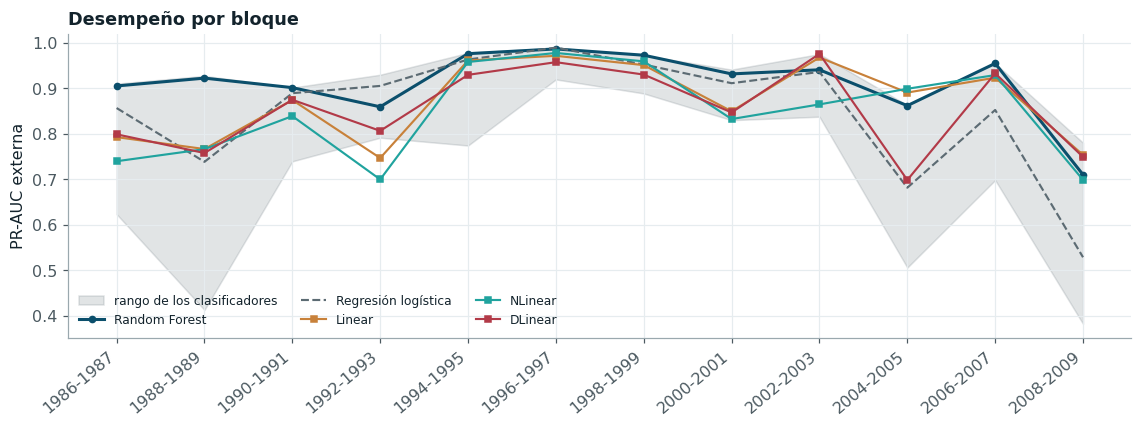

In [4]:
# PR-AUC por bloque de los modelos LTSF-Linear frente al rango de los siete clasificadores
x = np.arange(len(tabla)); etiquetas = [bloques[i] for i in tabla.index]
fig, ax = plt.subplots(figsize=(10.5, 4))
ax.fill_between(x, universo.min(axis=1), universo.max(axis=1), color=NEU, alpha=.18, label="rango de los clasificadores")
ax.plot(x, tabla[ref], "-o", color=RIO, lw=2, ms=4, label=NM[ref])
ax.plot(x, tabla["logistica"], "--", color=NEU, lw=1.4, label=NM["logistica"])
for m, c in zip(LTSF, (SED, CAU, ALE)):
    ax.plot(x, tabla[m], "-s", color=c, lw=1.4, ms=3.5, label=NM[m])
ax.set_xticks(x, etiquetas, rotation=40, ha="right"); ax.set_ylabel("PR-AUC externa")
ax.legend(ncol=3, fontsize=8, loc="lower left"); ax.set_title("Desempeño por bloque")
plt.tight_layout(); plt.show()

Las curvas de los tres modelos se mueven juntas y caen en los mismos bloques que los
clasificadores, lo que confirma que la dificultad de cada periodo depende del comportamiento del
río y no del modelo. En la mayoría de los bloques quedan por debajo del mejor clasificador y cerca
de la regresión logística, sin un bloque en que alguno de ellos destaque de manera sistemática.

## Evaluación en la prueba reservada

Con la configuración elegida por TPE sobre todo el entrenamiento (1947-2009), cada modelo se
reajustó y se evaluó una única vez en 2010-2026, como clasificador de la banda y como
pronosticador del caudal.

In [5]:
# PR-AUC en la prueba con IC por bootstrap estacionario, y RMSE del caudal frente a los regresores
fl = pickle.load(open(RESULTADOS / "final_ltsf.pkl", "rb"))
fin = {r["modelo"]: r for r in pickle.load(open(RESULTADOS / "final_clf.pkl", "rb"))}
freg = {r["modelo"]: r for r in pickle.load(open(RESULTADOS / "final_reg.pkl", "rb"))}
y = D.y_clf_test.values; qte = D.y_reg_test.values
L = longitud_bloque(y.astype(float))
rmse = lambda a: float(np.sqrt(np.mean((qte - a) ** 2)))
filas = []
for nombre, s in [(NM[ref], fin[ref]["pred_test"]), (NM["logistica"], fin["logistica"]["pred_test"])] + \
                 [(NM[m], fl[m]["pred_test"]) for m in LTSF]:
    ic = bootstrap_bloques(average_precision_score, y, s, media_bloque=L, n_boot=1000)
    filas.append({"Modelo": nombre, "PR-AUC prueba": ic["estimacion"],
                  "IC 95 % (bloques, BCa)": f"[{ic['ic_inf']:.3f}; {ic['ic_sup']:.3f}]"})
prueba = pd.DataFrame(filas).set_index("Modelo")
q_pers = np.sqrt(D.X_test.calamar_cuad.values)
reg = pd.DataFrame({"Pronóstico del caudal": [NM[m] for m in LTSF] + ["SVR (mejor regresor)", "Ridge", "Persistencia"],
                    "RMSE prueba (m³/s)": [rmse(fl[m]["q_pred_test"]) for m in LTSF]
                    + [rmse(freg["svr"]["pred_test"]), rmse(freg["ridge"]["pred_test"]), rmse(q_pers)]})
rm = [rmse(fl[m]["q_pred_test"]) for m in LTSF]
glue("ltsf_test_min", float(prueba.loc[list(LTSF.values()), "PR-AUC prueba"].min()), display=False)
glue("ltsf_test_max", float(prueba.loc[list(LTSF.values()), "PR-AUC prueba"].max()), display=False)
glue("ref_test", float(prueba.loc[NM[ref], "PR-AUC prueba"]), display=False)
glue("log_test", float(prueba.loc[NM["logistica"], "PR-AUC prueba"]), display=False)
glue("ltsf_rmse_min", min(rm), display=False); glue("ltsf_rmse_max", max(rm), display=False)
glue("svr_rmse", rmse(freg["svr"]["pred_test"]), display=False); glue("ridge_rmse", rmse(freg["ridge"]["pred_test"]), display=False)
glue("pers_rmse", rmse(q_pers), display=False)
glue("ltsf_mejora", 1 - max(rm) / rmse(q_pers), display=False)
glue("ltsf_univ", "solo la historia de Calamar" if all(fl[m]["params"]["canales"] == "calamar" for m in LTSF)
     else "la historia de Calamar y de Puerto Salgar", display=False)
display(prueba.reset_index().round(4))
reg.round(1)

,Modelo,PR-AUC prueba,"IC 95 % (bloques, BCa)"
0,Random Forest,0.9495,[0.911; 0.971]
1,Regresión logística,0.8910,[0.791; 0.946]
2,Linear,0.8998,[0.811; 0.947]
3,NLinear,0.9041,[0.812; 0.952]
4,DLinear,0.9069,[0.822; 0.953]


,Pronóstico del caudal,RMSE prueba (m³/s)
0,Linear,808.3
1,NLinear,802.5
2,DLinear,793.7
3,SVR (mejor regresor),642.8
4,Ridge,682.3
5,Persistencia,984.8


En la prueba reservada, los tres modelos alcanzan PR-AUC entre {glue:text}`ltsf_test_min:.3f` y
{glue:text}`ltsf_test_max:.3f`, por debajo de {glue:text}`ref_nombre`
({glue:text}`ref_test:.3f`) y por encima de la regresión logística ({glue:text}`log_test:.3f`), con
intervalos de confianza que se solapan con los de esta. El orden de la validación anidada se
mantiene, por tanto, fuera de muestra.

Como pronosticadores del caudal, sus RMSE en la prueba, entre {glue:text}`ltsf_rmse_min:,.0f` y
{glue:text}`ltsf_rmse_max:,.0f` m³/s, mejoran a la persistencia ({glue:text}`pers_rmse:,.0f` m³/s)
en al menos un {glue:text}`ltsf_mejora:.0%`, pero quedan por encima de la SVR
({glue:text}`svr_rmse:,.0f` m³/s) e incluso de Ridge ({glue:text}`ridge_rmse:,.0f` m³/s), que también
es lineal. La diferencia con Ridge no proviene de la forma del modelo sino de la información: las
tres configuraciones elegidas usan {glue:text}`ltsf_univ`, mientras que Ridge recibe además el caudal
de Puerto Salgar desfasado por su tiempo de tránsito, los armónicos estacionales y las variables
de distancia a la banda. A ello se suma que sus hiperparámetros se eligieron para clasificar la
banda y no para minimizar el error del caudal. El resultado indica que, en este río, el
conocimiento hidrológico codificado en los predictores aporta más que una representación más
elaborada de la historia del caudal.